**ANOMALY DETECTION OC-SVM**

In [3]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [ ]:
job_name = "net_v5_ms_ep20pre_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v5_ms_ep20pre"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False, 
    "moco_bot": False,
    "moco_ms": True,                
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                       # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,

    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                      # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [5]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all3',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm3",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [6]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-06 08:54:44,262 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...


2026-11-06 08:54:49,268 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:54:54,278 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:54:59,292 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:55:04,301 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:55:09,310 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:55:14,321 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08:55:19,331 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 4465e0559b3445bd9bbf12d944eaa8f4 to finish...
2026-11-06 08

BackendError: Not found. Response: {"status":404,"message":"No such run.","errorCode":null}.

In [13]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())               
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: net_v5_ms__ep20_0per | moco: net_v5_ms_ep20 | punti: encoder, pre_proj, proj_raw, post_proj 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.026738813857616485
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.052
min_flood_area = 0.000
score normali: 19.4304 ± 15.4572
score anomale: 3.6789 ± 13.4003
AUROC: 0.775


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-9.293826,549.0,88.0,1853.0,2314.0,0.036636,0.771440,0.228560,0.861852,0.361303
FA 10%,-5.304830,833.0,192.0,1569.0,2210.0,0.079933,0.653206,0.346794,0.812683,0.486139
FA 15%,-0.806611,1094.0,308.0,1308.0,2094.0,0.128226,0.544546,0.455454,0.780314,0.575184
FA 20%,2.958829,1279.0,438.0,1123.0,1964.0,0.182348,0.467527,0.532473,0.744904,0.621025
FA 25%,6.224259,1435.0,545.0,967.0,1857.0,0.226894,0.402581,0.597419,0.724747,0.654952
FA 30%,10.054692,1632.0,681.0,770.0,1721.0,0.283514,0.320566,0.679434,0.705577,0.692259


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.027396436091952796
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.053
min_flood_area = 0.000
score normali: 11.3655 ± 6.1771
score anomale: 6.0613 ± 6.1153
AUROC: 0.730


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.251172,348.0,92.0,2054.0,2310.0,0.038301,0.855121,0.144879,0.790909,0.244898
FA 10%,0.602304,587.0,186.0,1815.0,2216.0,0.077435,0.755620,0.244380,0.759379,0.369764
FA 15%,2.915664,876.0,310.0,1526.0,2092.0,0.129059,0.635304,0.364696,0.738617,0.488294
FA 20%,4.845345,1093.0,428.0,1309.0,1974.0,0.178185,0.544963,0.455037,0.718606,0.557227
FA 25%,6.572976,1304.0,551.0,1098.0,1851.0,0.229392,0.457119,0.542881,0.702965,0.612638
FA 30%,8.033735,1465.0,667.0,937.0,1735.0,0.277685,0.390092,0.609908,0.687148,0.646228


===== post_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.0022405950421688957
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 22.4164 ± 13.9011
score anomale: 7.7747 ± 16.1622
AUROC: 0.753


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-3.969844,573.0,98.0,1829.0,2304.0,0.040799,0.761449,0.238551,0.853949,0.372925
FA 10%,2.947565,858.0,227.0,1544.0,2175.0,0.094505,0.642798,0.357202,0.790783,0.492114
FA 15%,7.248650,1088.0,348.0,1314.0,2054.0,0.144879,0.547044,0.452956,0.757660,0.566962
FA 20%,10.937611,1301.0,481.0,1101.0,1921.0,0.200250,0.458368,0.541632,0.730079,0.621893
FA 25%,13.860134,1467.0,605.0,935.0,1797.0,0.251873,0.389259,0.610741,0.708012,0.655789
FA 30%,16.261594,1593.0,736.0,809.0,1666.0,0.306411,0.336803,0.663197,0.683985,0.673431


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.027,0.775
proj_raw,256,0.027,0.730
post_proj,256,0.002,0.753


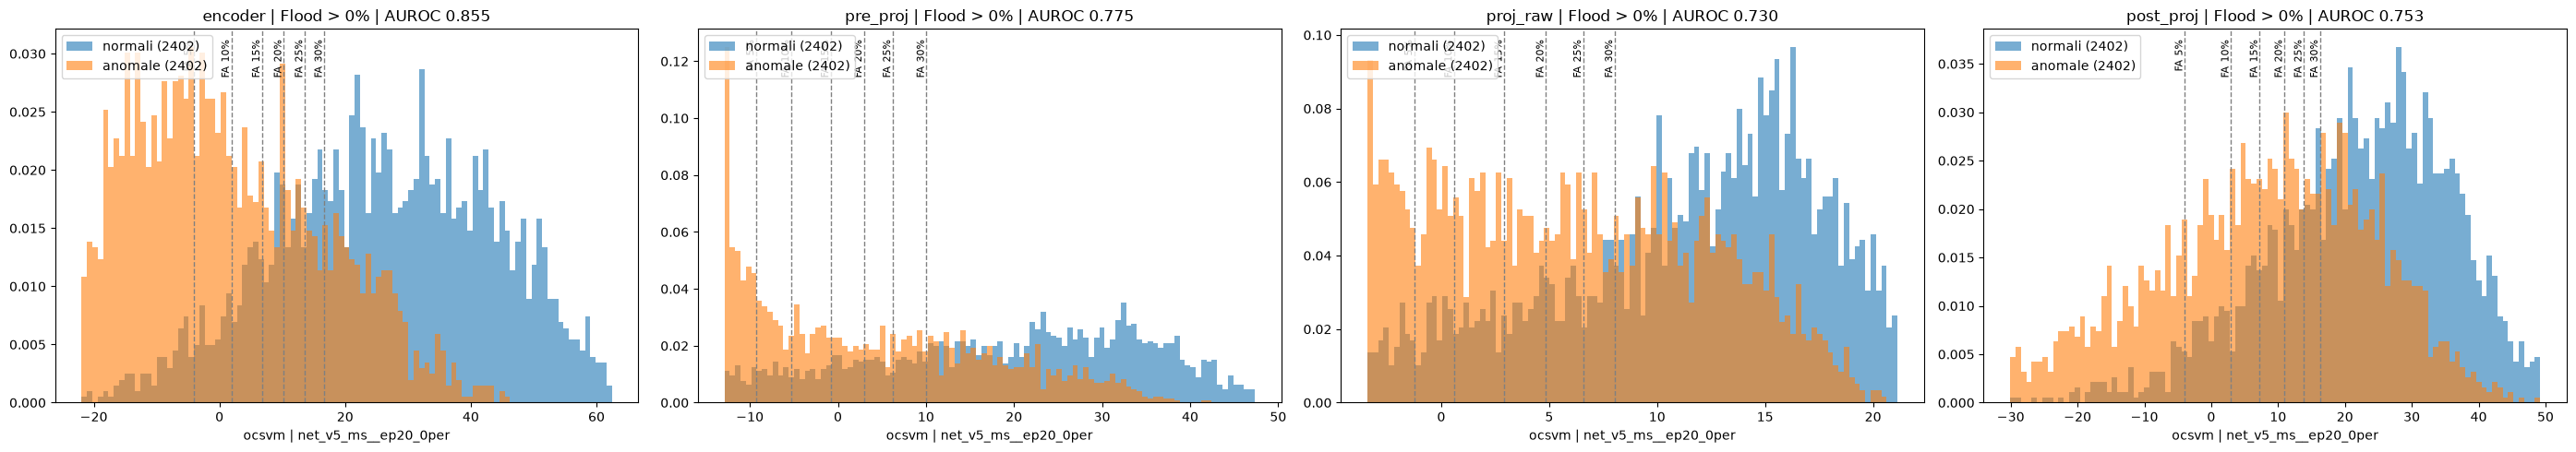

In [14]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

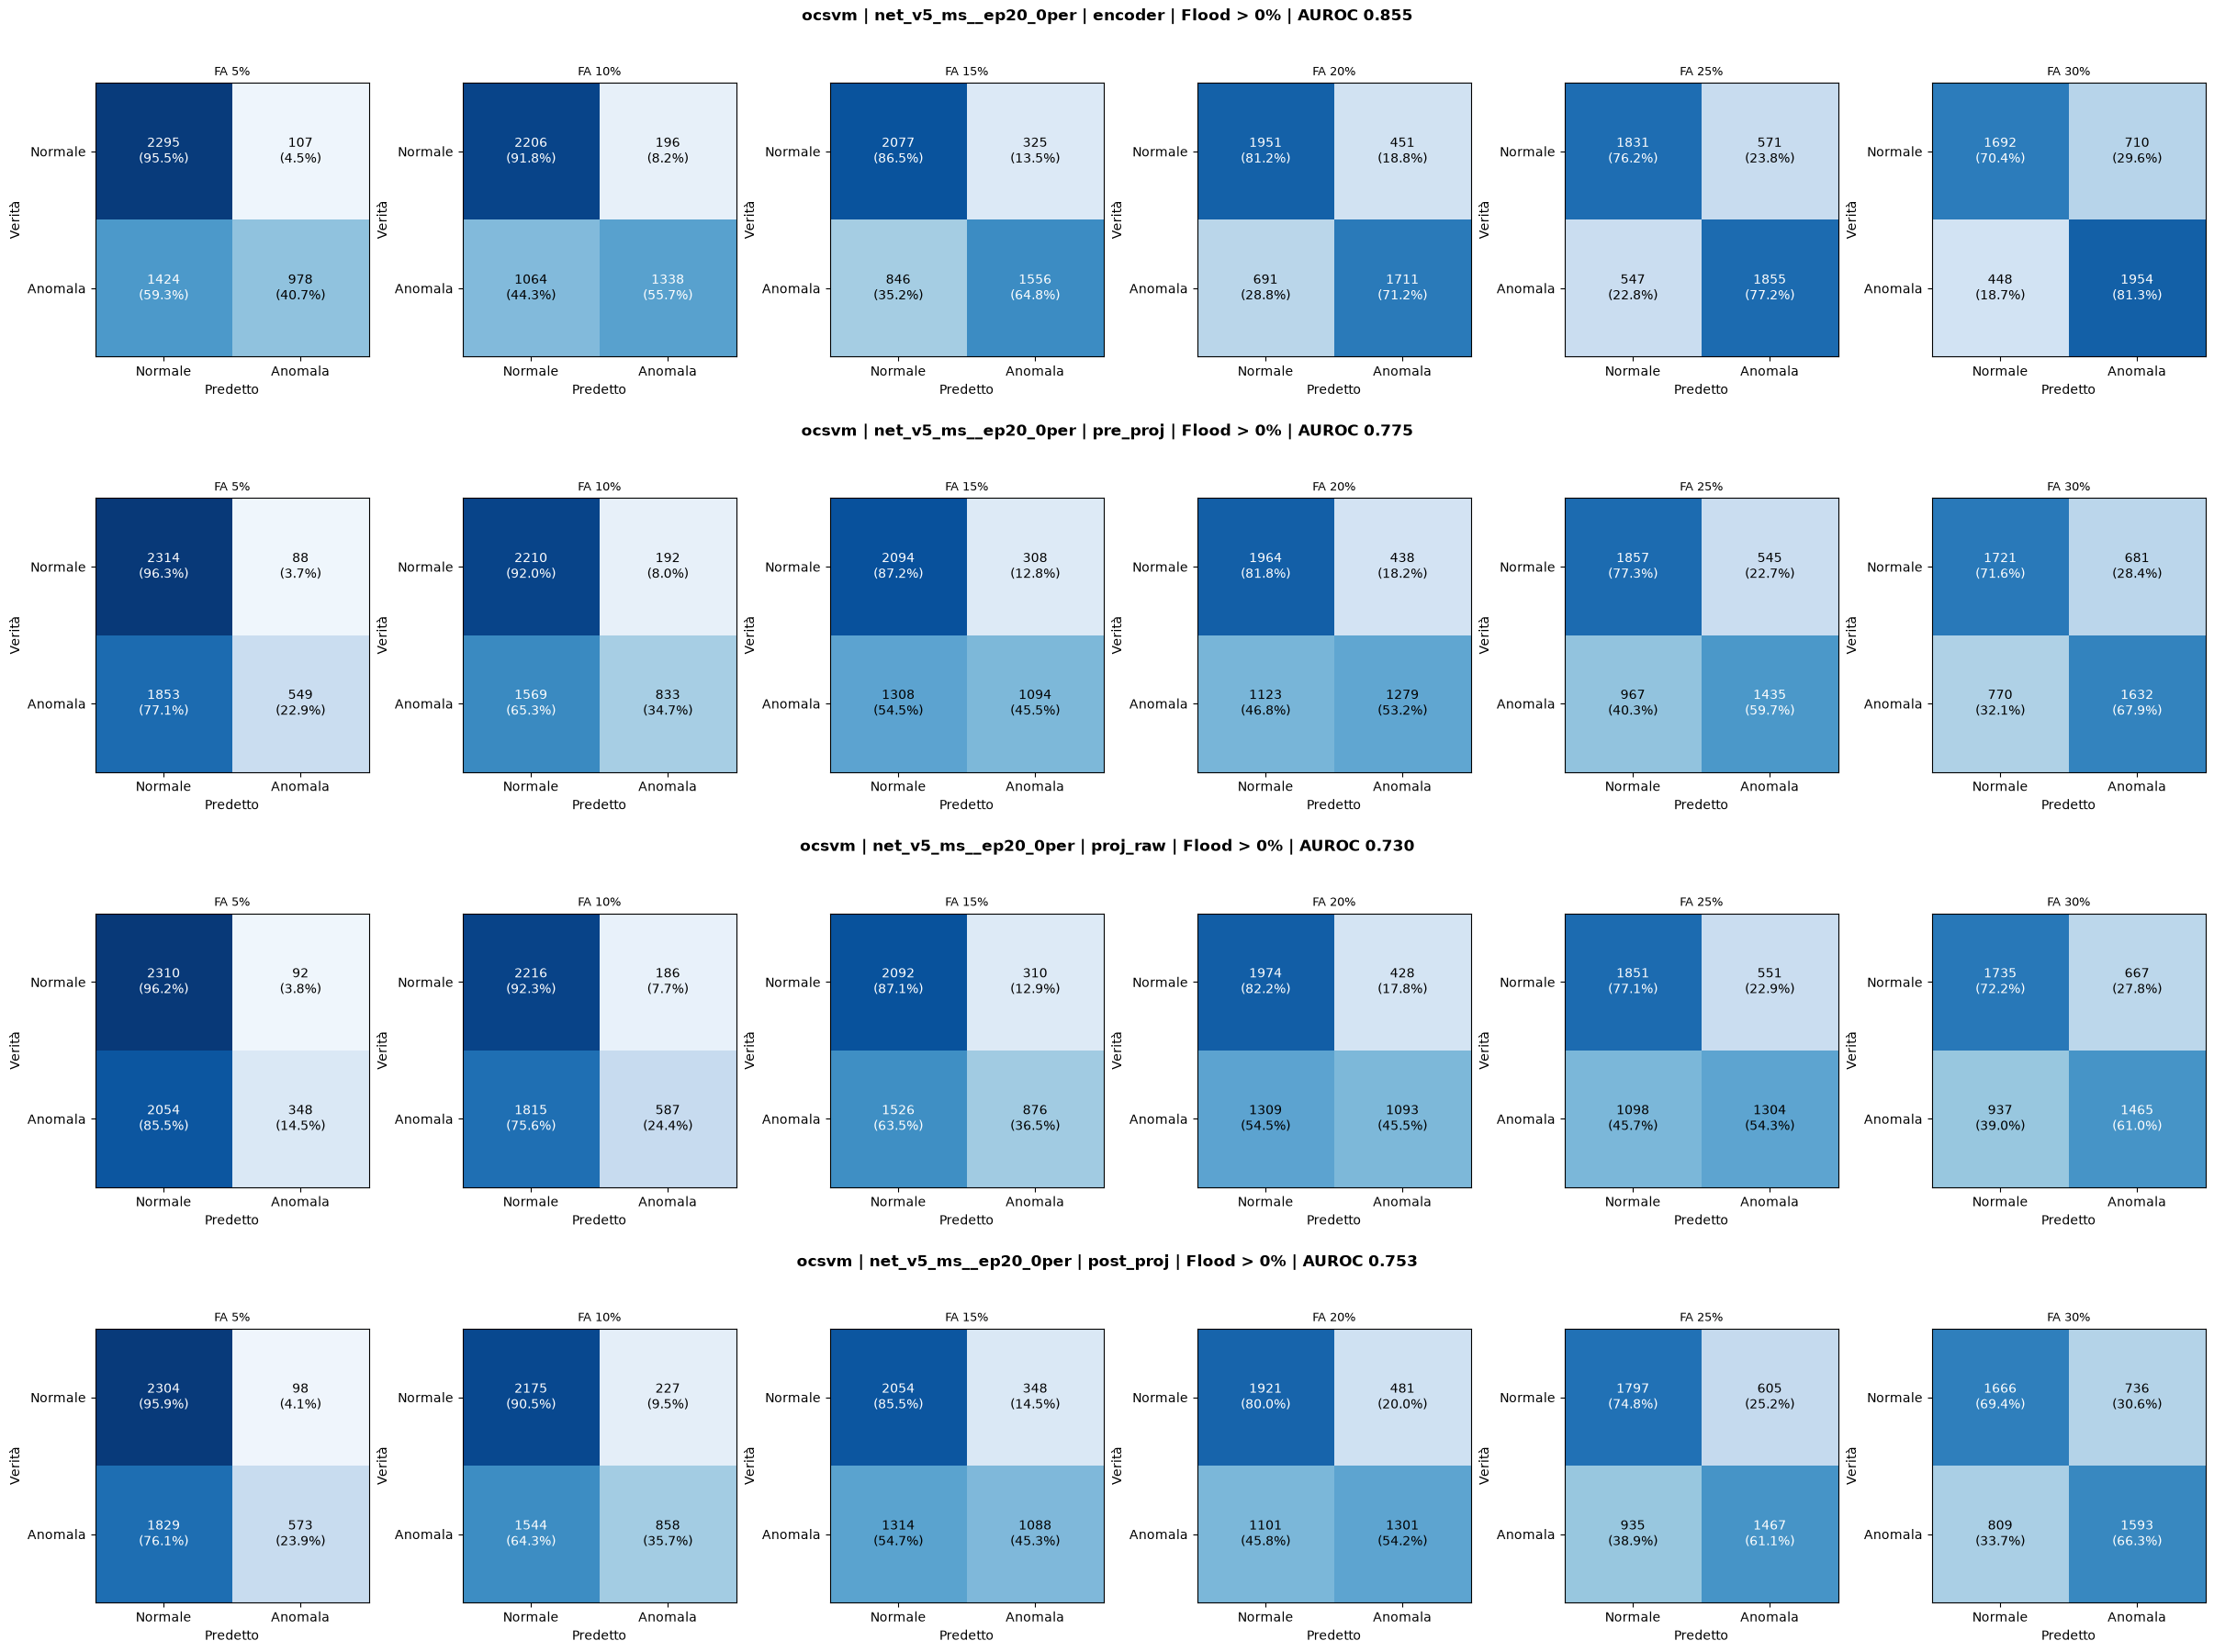

In [15]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [18]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                    
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}          
    righe.append({
        "k": k,
        "thr/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC validazione": auroc(md, n_val, a_val),                
    })

lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "thr/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC validazione": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_net_v5_ms__ep20_0per
job:           net_v5_ms__ep20_0per | moco: net_v5_ms_ep20 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.775 (ocsvm, whitening lw, 4096 componenti) 

forme: {'fit': (19893, 4096), 'thr': (2572, 4096), 'normal': (2402, 4096), 'anom': (2402, 4096)} 

Ledoit-Wolf shrinkage: 0.027
           thr/fit  AUROC validazione
k                                    
32           1.118              0.672
64           1.085              0.689
128          1.060              0.698
256          1.037              0.717
512          1.027              0.733
768          1.027              0.740
1024         1.035              0.745
1536         1.062              0.752
2048         1.107              0.756
3072         1.250            

In [ ]:
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

def carica(results_dir, punto):
    E = np.load(f"{results_dir}/{punto}/embeddings.npz")
    return {g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)
            for g in ("fit", "normal", "anom")}

enc = carica(RESULTS_DIR, "encoder")
pre = carica(RESULTS_DIR, "pre_proj")
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]

def md_lw(w):
    sc = StandardScaler().fit(w["fit"])
    w = {g: sc.transform(v) for g, v in w.items()}
    lw = LedoitWolf().fit(w["fit"])
    return {g: lw.mahalanobis(v) for g, v in w.items()}

s_enc = md_lw(enc)
s_pre = md_lw(pre)
s_cat = md_lw({g: np.concatenate([enc[g], pre[g]], axis=1) for g in enc})

from scipy.stats import rankdata
r = lambda s: rankdata(np.r_[s["normal"], s["anom"]]) / (len(s["normal"]) + len(s["anom"]))
s_fus = (r(s_enc) + r(s_pre)) / 2

for nome, s in (("encoder", np.r_[s_enc["normal"], s_enc["anom"]]),
                ("pre_proj", np.r_[s_pre["normal"], s_pre["anom"]]),
                ("encoder + pre_proj (concatenati)", np.r_[s_cat["normal"], s_cat["anom"]]),
                ("encoder + pre_proj (media dei ranghi)", s_fus)):
    print(f"{nome:38s}: AUROC {roc_auc_score(y, s):.3f}")

encoder                               : AUROC 0.855
pre_proj                              : AUROC 0.800
encoder + pre_proj (concatenati)      : AUROC 0.811
encoder + pre_proj (media dei ranghi) : AUROC 0.848


In [ ]:
from scipy.stats import spearmanr

tutti_enc = np.r_[s_enc["normal"], s_enc["anom"]]
tutti_pre = np.r_[s_pre["normal"], s_pre["anom"]]
print(f"correlazione di Spearman tra gli score: {spearmanr(tutti_enc, tutti_pre).correlation:.3f}")

correlazione di Spearman tra gli score: 0.782


In [ ]:
from scipy.stats import spearmanr

fa = 0.10                                                   

enc = carica(RESULTS_DIR, "encoder")
s_enc = md_lw(enc)
y = np.r_[np.zeros(len(enc["normal"])), np.ones(len(enc["anom"]))]
tutti = lambda s: np.r_[s["normal"], s["anom"]]

def rilevate(s):
    soglia = np.quantile(s["normal"], 1 - fa)
    return s["anom"] > soglia

righe = []
for punto in ("pre_proj", "proj_raw", "post_proj"):
    print(f"--- {punto} ---", flush=True)
    altro = carica(RESULTS_DIR, punto)
    s_alt = md_lw(altro)
    s_cat = md_lw({g: np.concatenate([enc[g], altro[g]], axis=1) for g in enc})

    r_enc, r_alt = rilevate(s_enc), rilevate(s_alt)
    righe.append({
        "punto": punto,
        "AUROC punto": roc_auc_score(y, tutti(s_alt)),
        "concatenati": roc_auc_score(y, tutti(s_cat)),
        "media ranghi": roc_auc_score(y, (r(s_enc) + r(s_alt)) / 2),
        "massimo ranghi": roc_auc_score(y, np.maximum(r(s_enc), r(s_alt))),
        "Spearman": spearmanr(tutti(s_enc), tutti(s_alt)).correlation,
        "solo encoder": np.mean(r_enc & ~r_alt),
        "solo punto": np.mean(~r_enc & r_alt),
    })

print(f"\nencoder da solo: AUROC {roc_auc_score(y, tutti(s_enc)):.3f}")
pd.DataFrame(righe).set_index("punto").round(3)

--- pre_proj ---
